# 03 — Historical Purchasing Behavior Calibration
## Online Retail II → Approved Shopify Catalog → Phase 4

**Objective.** Document and visualize the empirical purchasing behavior that will inform a deterministic synthetic 2026 order generator.

**Data contract.** Use the checksum-verified, published Silver v1 tables and a checksum-pinned approved-catalog manifest. The calibration itself is defined in `src/ecommerce/application/use_cases/historical_calibration.py`; this notebook **calls the same tested implementation** instead of maintaining a second model.

**Scope.** Descriptive historical calibration only. No synthetic transactions are generated; no S3, RDS, Shopify, Terraform, or other remote resources are modified. S3 access is read-only.

**Critical interpretation.** The original invoice timestamps are timezone-naive, source currency is not documented, the data mixes retail and wholesale-like behavior, and there are incomplete boundary months. Chart annotations and assumptions must reflect this.

## 1 — Reproducibility and inputs

Run with the project `ecommerce-analytics` kernel, starting from the repository root or its `notebooks/` directory. Requirements: the `historical`, `aws`, and `dev` project extras, plus `matplotlib`. The AWS profile must have read permissions for the landing bucket.

The pinned approved manifest is the **3,408-product eligibility boundary**. Outputs and figures are displayed in memory. A separate CLI persists a local report with exclusive-create semantics; this notebook does not overwrite artifacts.

In [1]:
from pathlib import Path
import sys

repo_root = Path.cwd().resolve()
if not (repo_root / "pyproject.toml").exists():
    repo_root = repo_root.parent
assert (repo_root / "pyproject.toml").exists(), "Launch from repository root or notebooks/"
sys.path.insert(0, str(repo_root / "src"))

import boto3
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from ecommerce.application.use_cases.catalog_approval import approved_catalog
from ecommerce.application.use_cases.historical_calibration import (
    calibrate_historical_behavior,
    calibration_sha256,
)
from ecommerce.pipelines.silver.audit import read_published_silver

AWS_PROFILE = "ecommerce-admin"
AWS_REGION = "eu-central-1"
BUCKET = "ecommerce-demo-landing-393e7fdc5c01861ae4e5c25ad6"
SILVER_PREFIX = "historical/online_retail_ii/silver/v1"
APPROVAL_KEY = (
    "historical/online_retail_ii/catalog_approval/v1/"
    "catalog-approval-unflagged-v1.json"
)
APPROVAL_SHA256 = "b348f9804564657828e55597df6cc18718933742f6d3b8a1165d2d49c18ab130"


## 2 — Read and verify immutable source assets

`read_published_silver` verifies file SHA-256 hashes, row counts, expected Silver tables, and Bronze/Silver lineage. `approved_catalog` verifies the explicitly approved catalog manifest checksum.

**Important:** the Silver tables intentionally do not contain fabricated Shopify GIDs. Synced identities in RDS are a distinct operational concern; we calibrate against historical source identities and approved product codes.

In [2]:
session = boto3.Session(profile_name=AWS_PROFILE, region_name=AWS_REGION)
s3 = session.client("s3")
tables, silver_manifest, bronze_manifest = read_published_silver(
    s3, BUCKET, SILVER_PREFIX
)
approved_codes = frozenset(
    approved_catalog(s3, BUCKET, APPROVAL_KEY, APPROVAL_SHA256)
)
profile = calibrate_historical_behavior(
    tables,
    approved_stock_codes=approved_codes,
    source_sha256=bronze_manifest["source_sha256"],
)
assert profile["schema_version"] == "historical-behavior-calibration-v2"
assert profile["eligible_stock_codes"] == len(approved_codes)
display(pd.DataFrame([
    {"table": name, "rows": len(frame)}
    for name, frame in sorted(tables.items())
]))
print("Bronze source SHA-256:", bronze_manifest["source_sha256"])
print("Approved catalog SHA-256:", APPROVAL_SHA256)
print("Calibration report SHA-256:", calibration_sha256(profile))
print("Report version:", profile["schema_version"])


,table,rows
0,cross_sheet_duplicates,22523
1,customers,5942
2,order_items,809561
3,orders,44876
4,product_variants,4646
5,products,4646
6,quarantine,235287
7,returns_adjustments,21374


Bronze source SHA-256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980
Approved catalog SHA-256: b348f9804564657828e55597df6cc18718933742f6d3b8a1165d2d49c18ab130
Calibration report SHA-256: 9d0b8aa5a331434d889bef86c1d16ad2bb8dc3528edf42b04bbe8a841da6888a
Report version: historical-behavior-calibration-v2


## 3 — Population reconciliation and approval coverage

A positive line belongs to the simulated merchandise population only if it is both classified as a positive source sale and present in the **approved catalog**. This excludes flagged/review merchandise and non-merchandise codes.

The approved-line share is a **line coverage measure**, not a revenue share, conversion rate, or proof that excluded merchandise can be substituted freely.

,metric,count
0,All identifiable historical customers,5942
1,All customer-linked source invoices,44876
2,Invoices with approved positive merchandise,34391
3,Approved positive merchandise lines,457255
4,Excluded positive merchandise lines,330932
5,Source cancellation-flagged lines,18446


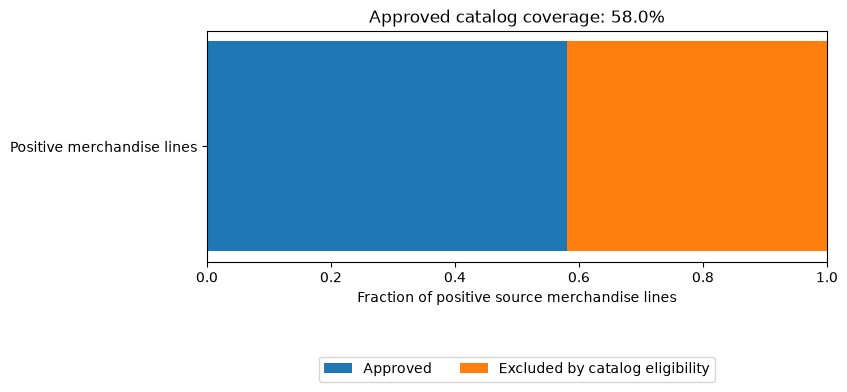

In [3]:
summary = pd.DataFrame([
    ("All identifiable historical customers", profile["customers_total"]),
    ("All customer-linked source invoices", profile["orders_total"]),
    ("Invoices with approved positive merchandise", profile["approved_positive_orders"]),
    ("Approved positive merchandise lines", profile["approved_positive_lines"]),
    ("Excluded positive merchandise lines", profile["excluded_positive_lines"]),
    ("Source cancellation-flagged lines", profile["cancelled_source_lines"]),
], columns=["metric", "count"])
display(summary)
positive_total = profile["approved_positive_lines"] + profile["excluded_positive_lines"]
approved_share = profile["approved_positive_lines"] / positive_total
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(["Positive merchandise lines"], [approved_share], label="Approved")
ax.barh(["Positive merchandise lines"], [1-approved_share], left=[approved_share],
        label="Excluded by catalog eligibility")
ax.set_xlim(0, 1)
ax.set_xlabel("Fraction of positive source merchandise lines")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.55), ncol=2)
ax.set_title(f"Approved catalog coverage: {approved_share:.1%}")
plt.show()


## 4 — Customer-order frequency

All **5,942 canonical historical customers** are included in this distribution, including those with **zero approved-positive invoices**. Invoices—not individual lines—are counted.

The quantiles refer to counts over the *shared historical observation period*. They are **not annualized purchase rates** and do not adjust for differing customer tenures. High-frequency outliers require careful handling in the generator.

,p50,p90,p95,p99
Approved invoices per customer,3,12,19,42


,segment,customers
0,No approved orders,188
1,One approved order,1633
2,Two or more approved orders,4121


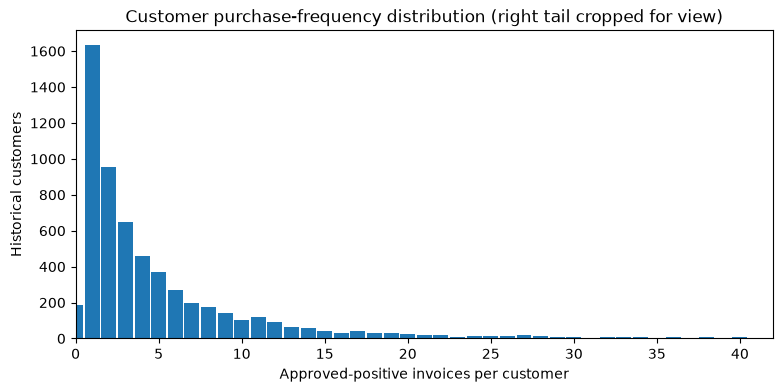

In [4]:
customer_hist = pd.Series({
    int(key): int(value)
    for key, value in profile["customer_order_count_histogram"].items()
}).sort_index()
customer_quantiles = profile["customer_order_count_percentiles"]
display(pd.DataFrame([customer_quantiles], index=["Approved invoices per customer"]))
display(pd.DataFrame({
    "segment": ["No approved orders", "One approved order", "Two or more approved orders"],
    "customers": [
        int(customer_hist.get(0, 0)),
        int(customer_hist.get(1, 0)),
        int(customer_hist.loc[customer_hist.index >= 2].sum()),
    ],
}))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(customer_hist.index, customer_hist.values, width=0.9)
ax.set_xlim(0, max(10, customer_quantiles["p99"]))
ax.set_xlabel("Approved-positive invoices per customer")
ax.set_ylabel("Historical customers")
ax.set_title("Customer purchase-frequency distribution (right tail cropped for view)")
plt.show()


## 5 — Basket composition and robust percentiles

Each eligible invoice forms **one observed basket**. Historical baskets can be wholesale-sized, so visualizing a trimmed x-axis is useful—but **no source baskets are deleted** by the chart.

We will choose a documented, configurable basket-size cap only when designing the simulator. The `p95` and `p99` values are candidates for sensitivity analysis, not automatically accepted caps.

,basket_lines,basket_units
p50,9,90
p90,30,319
p95,40,482
p99,70,1512


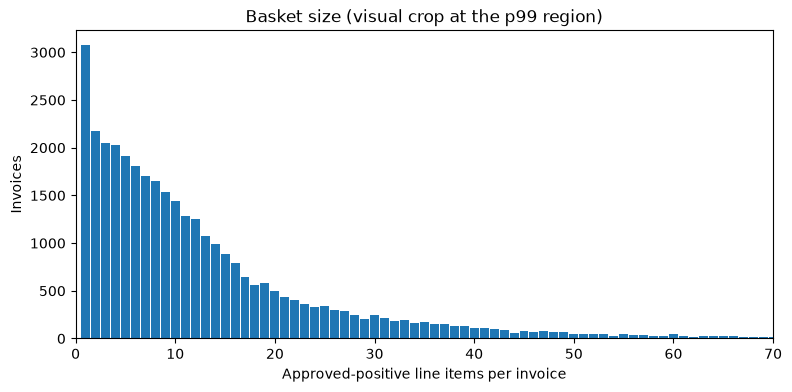

In [5]:
basket_hist = pd.Series({
    int(key): int(value)
    for key, value in profile["basket_line_count_histogram"].items()
}).sort_index()
display(pd.DataFrame({
    "basket_lines": profile["basket_line_count_percentiles"],
    "basket_units": profile["basket_unit_count_percentiles"],
}))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(basket_hist.index, basket_hist.values, width=0.9)
ax.set_xlim(0, max(10, profile["basket_line_count_percentiles"]["p99"]))
ax.set_xlabel("Approved-positive line items per invoice")
ax.set_ylabel("Invoices")
ax.set_title("Basket size (visual crop at the p99 region)")
plt.show()


## 6 — Monthly seasonality with calendar exposure

Raw monthly invoice counts are misleading for incomplete boundary months. Divide eligible invoice count by calendar days from the **first to last source invoice date inclusive**. Because the first and final dates may only be partially observed, these are approximate *calendar exposure rates*, not verified opening-hour rates.

Use this for relative seasonal behavior; **do not treat rates as 2026 demand volumes**. Historical order volume and customer tenure require a separate scaling policy.

,orders,exposure_days,orders_per_calendar_day
2009-12,1411,31,45.516129
2010-01,888,31,28.645161
2010-02,1040,28,37.142857
2010-03,1429,31,46.096774
2010-04,1243,30,41.433333
2010-05,1278,31,41.225806
2010-06,1381,30,46.033333
2010-07,1253,31,40.419355
2010-08,1204,31,38.838710
2010-09,1526,30,50.866667


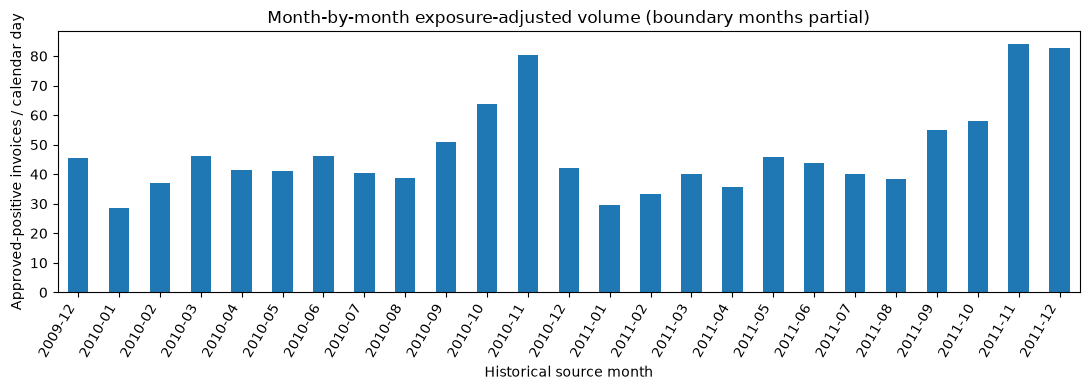

In [6]:
monthly = pd.DataFrame.from_dict(
    profile["monthly_orders_per_exposure_day"], orient="index"
).sort_index()
monthly["orders_per_calendar_day"] = monthly["orders"] / monthly["exposure_days"]
display(monthly)
fig, ax = plt.subplots(figsize=(11, 4))
monthly["orders_per_calendar_day"].plot.bar(ax=ax)
ax.set_ylabel("Approved-positive invoices / calendar day")
ax.set_xlabel("Historical source month")
ax.set_title("Month-by-month exposure-adjusted volume (boundary months partial)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


## 7 — Weekday and hour-of-day behavior

Weekday rates likewise divide by observed calendar days. **Saturday is unusually low** in the historical source; the notebook preserves that observation and flags it for simulation-policy review rather than silently filling it.

The source hours have **no verified timezone**. They are only *naive source-clock hours*, not UTC hours for generated events. A source-clock-to-UTC simulation convention must be explicitly selected and documented later.

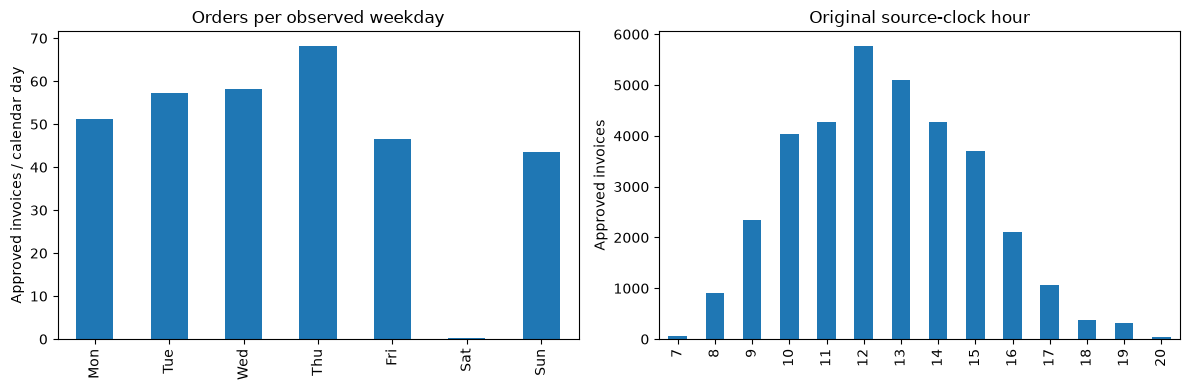

,orders,exposure_days,orders_per_calendar_day
Mon,5376,105,51.200000
Tue,6081,106,57.367925
Wed,6164,106,58.150943
Thu,7229,106,68.198113
Fri,4946,106,46.660377
Sat,28,105,0.266667
Sun,4567,105,43.495238


In [7]:
weekday = pd.DataFrame.from_dict(
    profile["weekday_orders_per_exposure_day"], orient="index"
)
weekday.index = weekday.index.astype(int)
weekday = weekday.sort_index()
weekday["orders_per_calendar_day"] = weekday["orders"] / weekday["exposure_days"]
weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
hours = pd.Series({
    int(key): int(value) for key, value in profile["hour_order_counts"].items()
}).sort_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
weekday["orders_per_calendar_day"].plot.bar(ax=axes[0])
axes[0].set_title("Orders per observed weekday")
axes[0].set_ylabel("Approved invoices / calendar day")
hours.plot.bar(ax=axes[1])
axes[1].set_title("Original source-clock hour")
axes[1].set_ylabel("Approved invoices")
plt.tight_layout()
plt.show()
display(weekday)


## 8 — Cancellation semantics

Report **distinct source invoices containing at least one cancellation-flagged line** alongside cancellation-line counts. This is an *invoice-level incidence*, **not a confirmed refund rate or lifecycle conversion probability**. A cancellation invoice may be separate from its original invoice, so numerator and denominator are descriptive only.

Before synthetic returns/cancellations are implemented, we must design explicit order-to-return matching semantics and document whether the generator creates a cancellation event, a return, or a refund.

In [8]:
cancelled = profile["source_orders_with_cancellation_lines"]
all_orders = profile["orders_total"]
display(pd.DataFrame([
    ("All customer-linked source invoices", all_orders),
    ("Invoices with ≥1 cancellation line", cancelled),
    ("Invoices without cancellation lines",
     profile["source_orders_without_cancellation_lines"]),
    ("Approved-positive invoices also containing cancellation lines",
     profile["approved_positive_orders_with_cancellation_lines"]),
], columns=["metric", "count"]))
print(f"Observed cancellation-flagged invoice incidence: {cancelled / all_orders:.2%}")
print("This is NOT a verified return or refund rate.")


,metric,count
0,All customer-linked source invoices,44876
1,Invoices with ≥1 cancellation line,7901
2,Invoices without cancellation lines,36975
3,Approved-positive invoices also containing can...,0


Observed cancellation-flagged invoice incidence: 17.61%
This is NOT a verified return or refund rate.


## 9 — Purpose and proposed 2026 simulation decisions

This notebook has two roles: **(a) reproducible historical evidence**, and **(b) the rationale for choices the deterministic 2026 generator will make**. Sections 1–8 measure what the 2009–2011 source actually contains. This section distinguishes those measurements from future simulator assumptions. **All policies below are proposals awaiting explicit review; no generator is implemented or approved by this notebook.**

### Decision A — Customer activity and order volume

**Evidence:** 5,942 distinct identifiable customers; 188 had no approved-positive orders; 1,633 had exactly one. Eligible invoices per customer are p50 = **3**, p95 = **19**, p99 = **42**, measured across the historical observation period, **not per year**.

**Proposed simulation rule:** preserve all canonical customers and relative heterogeneity rather than giving everyone the historical mean. Define an explicit target 2026 volume (for example, a user-approved total annual order budget) and a versioned zero-purchase-customer policy. Historical counts must not be naively annualized; account for incomplete customer tenures and the 2026 observation window. Until a target and tenure/activation policy are approved, the generator should fail closed rather than silently invent its order rate.

**Validation to add:** target-volume reconciliation, customer activity segment distribution, stable customer sampling under reruns and arbitrary batch boundaries.

### Decision B — Retail and wholesale-like basket behavior

**Evidence:** approved-positive baskets have p50/p95/p99 **9/40/70 lines**, versus **90/482/1,512 units**. **457,255** positive lines belong to the approved catalog; **330,932** other positive lines do not. These are **two distinct quantities**: line count and summed units.

**Proposed simulation rule:** consider a configurable bounded-retail mode and a separately labeled wholesale-tail mode. Evaluate p95 versus p99 line caps *as sensitivity scenarios*, not as assumed true limits. Model unit quantity per line separately from basket lines; enforce only the checksum-approved stock-code universe. Do not substitute excluded stock codes automatically and do not claim that a cap represents actual historical retail segmentation without additional evidence.

**Validation to add:** basket line/unit percentiles by mode, catalog membership for every generated item, and reproducible product-selection and quantity sampling.

### Decision C — Saturday and source-clock seasonality

**Evidence:** weekday exposure-adjusted orders are very uneven; Saturday has **28** eligible invoices across **105** calendar Saturdays, or approximately **0.27 orders per Saturday**, whereas Thursday is approximately **68.20 per Thursday**. Historical invoice clock-hours are *naive*; no source timezone has been verified.

**Proposed simulation rule:** preserve an `observed_weekday` scenario as the historical baseline and compare it with an explicitly labeled `smoothed_weekday` scenario, for which smoothing strength must be specified and tested. Never silently fill in the Saturday gap or declare one pattern universally correct. For synthetic event times, choose a separate documented UTC policy rather than relabeling naive source hours as UTC.

**Validation to add:** weekday rate comparisons, deterministic date/hour selection, leap-year/calendar handling, and no generated timestamp outside the frozen half-open backfill interval.

### Cross-cutting controls and unresolved choices

- **Reproducibility:** fixed seed + model/config version + published source and catalog hashes; window-stable event IDs and random streams independent of batch sizes; immutable S3 manifests with committed `[start_utc, cutoff_utc)` intervals.
- **Cutoff:** capture UTC once at invocation start, keep it fixed for the run, and continue later runs from the previous **committed** exclusive cutoff.
- **Money:** source currency is absent; pricing/currency for synthetic 2026 data needs an *explicit simulated assumption* before monetary fields are emitted.
- **Cancellations:** 7,901 of 44,876 source invoices contain cancellation-flagged lines (17.61%); this is **not** an inferred refund probability. Model cancellation/return events only after their relationship to original orders is specified.
- **Operational boundary:** historical backfill goes to versioned S3; no wholesale creation of past Shopify orders or RDS OLTP transactions. The live event generator is a separate controlled phase.

**Decision status:** *Proposed — pending review of activity/volume target, basket modes/caps, weekday smoothing, timestamp convention, currency and cancellation behavior.* The associated Notion Engineering Runbook records review status and implementation decisions; this notebook preserves the analytical **why** behind them.



## 10 — Interpretation, next steps and reproducibility

**Observed evidence** (generated dynamically above): source customer-frequency, basket-size and approved product distributions; monthly and weekday calendar exposure; source-clock hour pattern; cancellation-line and cancellation-invoice counts.

**Additional checks before Phase 4 generation:**
1. Customer activity/tenure model and volume scaling from 2009–2011 to 2026.
2. Sensitivity analyses for `p95` versus `p99` basket caps; separately preserve an optional wholesale segment.
3. Saturday handling: observed pattern, smoothed pattern, and comparison of their aggregate effects.
4. UTC simulation time policy; do not re-label naive historical times as UTC.
5. Currency and synthetic unit-price policy: source currency is unknown.
6. A restart-safe seed/identity scheme and exclusive invocation-time UTC cutoff, with immutable versioned manifests.

**Acceptance before backfill:** independently verified catalog identity mapping completion, explicit simulation configuration and deterministic offline rerun checks. The generator and live event producer are not built in this notebook.

In [9]:
display(Markdown("### Source warnings and reproducibility"))
for note in profile["limitations"]:
    print("•", note)
print("Calibration SHA-256:", calibration_sha256(profile))
print("This notebook is read-only. Use the CLI to save the versioned calibration report.")


### Source warnings and reproducibility

• Descriptive historical distribution, not a fitted predictive model
• Source invoice dates are timezone naive
• Source currency not recorded
• Anonymous customer transactions excluded from customer-linked Silver
• Cancellations do not prove matched refunds
• Order-level cancellation flags mean at least one line flagged; not a refund rate
• Invoice date span exposure includes incomplete boundary dates
• Customer order frequency counts cover a shared observation window, not customer tenure
• Only approved, positive merchandise lines calibrate synthetic baskets
Calibration SHA-256: 9d0b8aa5a331434d889bef86c1d16ad2bb8dc3528edf42b04bbe8a841da6888a
This notebook is read-only. Use the CLI to save the versioned calibration report.
